# Isogeometric layer: evaluate, refine and sample NURBS models

A reader of a NURBS file (an MFEM `NURBS mesh`, Kratos CAD JSON, STEP, IGES) hands you two things:
the **sampling**, Lagrange cells every viewer and operation understands, and the **model** it was
sampled from, in `mesh.info["nurbs"]` or `mesh.info["brep"]`: knot vectors, weights, control nets,
NURBS fields, trimming loops. Operations on the sampling never touch the model. The isogeometric
layer does:

- **`iga_refine`** inserts knots (h) and elevates degrees (p), *exactly*: the geometry, the
  parametrisation, the NURBS fields and a trimmed face's trimming loops do not change;
- **`iga_evaluate`** returns points, first derivatives, unit normals and the trimming test at
  parametric coordinates;
- **`iga_sample`** turns a model into cells again.

See [isogeometric layer](../../doc/iga.md).

In [1]:
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

os.environ.setdefault('MESHIOPLUSPLUS_LOG_LEVEL', 'error')
os.environ.setdefault('VTK_DEFAULT_OPENGL_WINDOW', 'vtkEGLRenderWindow')  # no X server
import meshioplusplus as mp  # noqa: E402

# Head-less, static rendering (no display / live server needed).
pv.OFF_SCREEN = True
pv.set_jupyter_backend('static')
TMP = tempfile.mkdtemp()
REPO = os.path.dirname(os.path.dirname(os.getcwd()))
MESHES = os.path.join(REPO, 'tests', 'python', 'meshes')


def to_grid(mesh):
    """A PyVista grid of a meshio++ mesh, through a temporary .vtu. Quadratic cells are
    tessellated first, so a curved cell is drawn curved."""
    if any(c.type in ('quad9', 'hexahedron27') for c in mesh.cells):
        mesh = mp.tessellate(mesh, levels=3, fields=False).mesh
    target = os.path.join(TMP, 'render.vtu')
    mp.write(target, mesh)
    return pv.read(target)


def render(mesh, title, scalars=None, cmap='viridis', view=(1.0, -1.4, 1.2), show_edges=True, ax=None):
    """Render with PyVista (embedded through matplotlib), or the points when GL is unavailable."""
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(8, 5.5))
    try:
        grid = to_grid(mesh)
        pl = pv.Plotter(off_screen=True, window_size=(900, 640))
        kwargs = {'show_edges': show_edges, 'edge_color': '#333333', 'line_width': 0.3}
        if scalars is not None:
            kwargs.update(scalars=scalars, cmap=cmap, scalar_bar_args={'title': scalars})
        else:
            kwargs['color'] = '#2ec4b6'
        pl.add_mesh(grid, **kwargs)
        pl.view_vector(view, viewup=(0, 0, 1))
        pl.reset_camera()
        img = pl.screenshot(return_img=True)
        pl.close()
        ax.imshow(img)
    except Exception as exc:  # pragma: no cover - head-less GL fallback
        print('PyVista render skipped:', exc)
        p = np.asarray(mesh.points)
        ax.scatter(p[:, 0], p[:, 1], s=1)
        ax.set_aspect('equal')
    ax.set_title(title)
    ax.axis('off')
    if own:
        plt.tight_layout()
        plt.show()

## A NURBS surface: refinement changes the net, not the surface

`square-disc-nurbs-patch` is a quadratic rational patch (a disc as a bent square) from the MFEM
reader's fixtures. We refine it three ways and plot the **control net** (the points the model is
made of) over the surface they define. Elevating the degree adds control points and continuity
without cutting the patch; knot insertion adds them where we ask; both leave the surface alone.

<meshio++ mesh object>
  Number of points: 46
  Number of cells:
    quad9: 9
    line3: 10
  Cell sets: attribute_1, boundary_1, boundary_2, boundary_3, boundary_4
  Cell data: mfem:attribute
patches: 5  degrees: [[2, 2], [2, 2]]


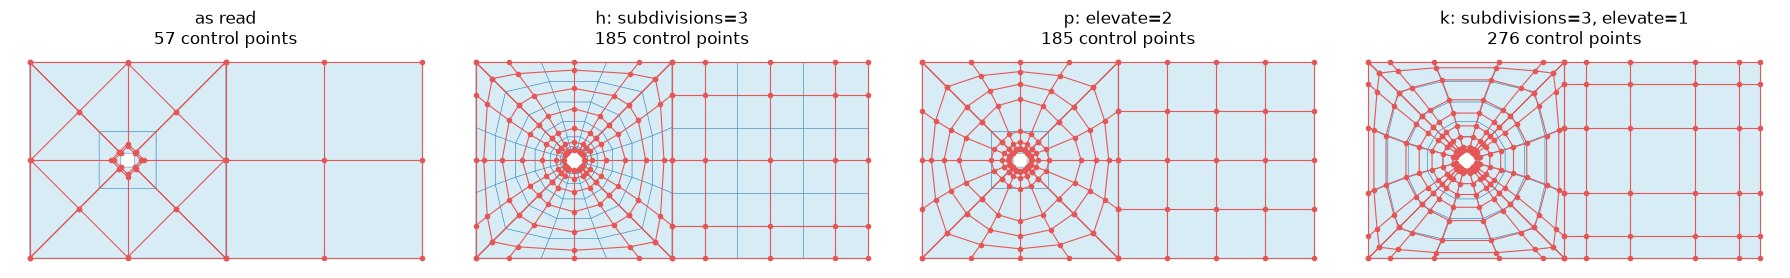

In [2]:
NURBS = os.path.join(MESHES, 'mfem', 'nurbs')
disc = mp.read(os.path.join(NURBS, 'square-disc-nurbs-patch.mesh'), file_format='mfem')
info = disc.info['nurbs']
print(disc)
print('patches:', len(info['patches']), ' degrees:', [p['degrees'].tolist() for p in info['patches']][:2])

variants = {
    'as read': disc,
    'h: subdivisions=3': mp.iga_refine(disc, subdivisions=3),
    'p: elevate=2': mp.iga_refine(disc, elevate=2),
    'k: subdivisions=3, elevate=1': mp.iga_refine(disc, subdivisions=3, elevate=1),
}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, (title, m) in zip(axes, variants.items()):
    for patch in m.info['nurbs']['patches']:
        n = [len(k) - int(p) - 1 for k, p in zip(patch['knots'], patch['degrees'])]
        net = patch['control_points'].reshape(n[1], n[0], -1)
        for row in net:
            ax.plot(row[:, 0], row[:, 1], color='#e45756', lw=0.8, marker='o', ms=3)
        for col in net.transpose(1, 0, 2):
            ax.plot(col[:, 0], col[:, 1], color='#e45756', lw=0.8)
    cells = m.cells[0].data[:, :4]
    for quad in m.points[cells]:
        ax.fill(quad[:, 0], quad[:, 1], facecolor='#cfe8f3', edgecolor='#3182bd', lw=0.4, alpha=0.8)
    npts = sum(len(p['weights']) for p in m.info['nurbs']['patches'])
    ax.set_title(f'{title}\n{npts} control points')
    ax.set_aspect('equal')
    ax.axis('off')
plt.tight_layout()
plt.show()

"Exactly" is checkable. Evaluate the original and every refined patch at the same random
parameters, positions and first derivatives:

In [3]:
rng = np.random.default_rng(0)
patch0 = info['patches'][0]
lo = [patch0['knots'][d][patch0['degrees'][d]] for d in range(2)]
hi = [patch0['knots'][d][-patch0['degrees'][d] - 1] for d in range(2)]
uv = lo + (np.array(hi) - np.array(lo)) * rng.uniform(size=(2000, 2))
ref = mp.iga_evaluate(disc, uv, derivatives=1)
for title, m in list(variants.items())[1:]:
    got = mp.iga_evaluate(m, uv, derivatives=1)
    print(f"{title:32s} max |dx| = {abs(got['points'] - ref['points']).max():.2e}"
          f"   max |dx/du| = {abs(got['derivatives'] - ref['derivatives']).max():.2e}")

h: subdivisions=3                max |dx| = 3.55e-15   max |dx/du| = 1.95e-14
p: elevate=2                     max |dx| = 4.44e-15   max |dx/du| = 1.78e-14
k: subdivisions=3, elevate=1     max |dx| = 3.55e-15   max |dx/du| = 3.20e-14


## Evaluation: derivatives and normals of the Scordelis-Lo roof

A rational patch of degrees (2, 1): an 80° arc of a cylinder of radius 25 (Kratos CAD JSON). The
model gives positions and tangents anywhere, not just at the sampled nodes. Normals follow from the
tangents; for a cylinder they are radial.

radius of every evaluated point (axis y): [25.]
normal vs radial direction, worst |n . r|: 0.9999999999999999


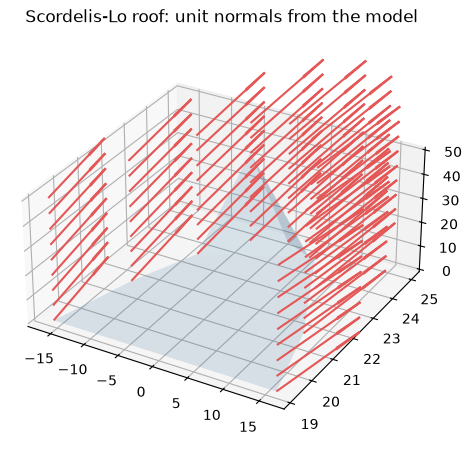

In [4]:
roof = mp.read(os.path.join(MESHES, 'cad_json', 'cylindrical_roof.cad.json'))
face_patch = roof.info['brep']['patches'][0]
g = np.linspace(0.0, 1.0, 9)
u0, u1 = face_patch['knots'][0][2], face_patch['knots'][0][-3]
v0, v1 = face_patch['knots'][1][1], face_patch['knots'][1][-2]
uv = np.array([[a, b] for b in v0 + (v1 - v0) * g for a in u0 + (u1 - u0) * g])
ev = mp.iga_evaluate(roof, uv, derivatives=1)
print('radius of every evaluated point (axis y):',
      np.unique(np.round(np.hypot(ev['points'][:, 0], ev['points'][:, 2]), 12)))
radial = ev['points'] * np.array([1, 0, 1])
radial /= np.linalg.norm(radial, axis=1)[:, None]
print('normal vs radial direction, worst |n . r|:', np.abs((ev['normals'] * radial).sum(1)).min())

fig = plt.figure(figsize=(8, 5.5))
ax = fig.add_subplot(projection='3d')
p, nrm = ev['points'], ev['normals']
ax.plot_trisurf(p[:, 0], p[:, 2], p[:, 1], alpha=0.15, color='#3182bd')
ax.quiver(p[:, 0], p[:, 2], p[:, 1], nrm[:, 0], nrm[:, 2], nrm[:, 1], length=4, color='#e45756')
ax.set_title('Scordelis-Lo roof: unit normals from the model')
ax.set_box_aspect((1, 1, 0.5))
plt.show()

## A trimmed face: the loops stay exact

The plate with a hole is a degree-(2, 2) face bounded by a square loop and a circular hole made
of four rational arcs. Refining the face (here: elevate to degree (3, 4) and cut every span in
three) changes its net, not its trim: the trimming curves live in the face's parameter space,
which neither refinement moves. `iga_evaluate` reports for each point whether it is inside the
loops, by the exact curves, not by the cells of the sampling.

degrees [2, 2] -> [3, 4]    control points 9 -> 42
trimming curves identical: True
inside test agrees before and after refinement: True


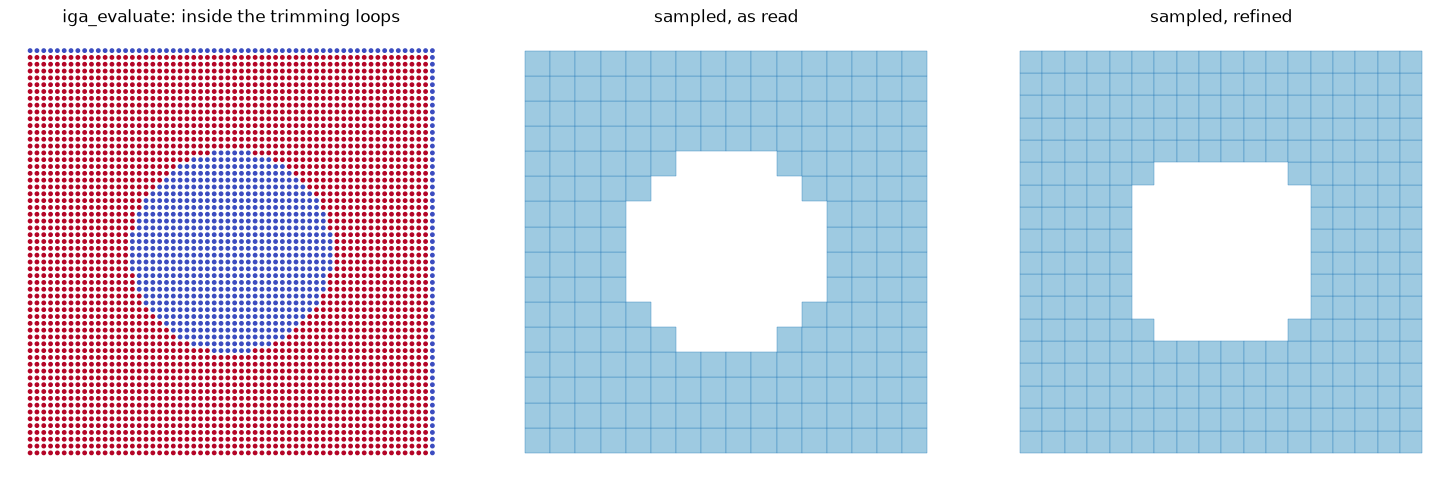

In [5]:
plate = mp.read(os.path.join(MESHES, 'cad_json', 'plate_with_hole.cad.json'))
fine = mp.iga_refine(plate, subdivisions=(3, 3), elevate=(1, 2))
pb, fb = plate.info['brep'], fine.info['brep']
print('degrees', pb['patches'][0]['degrees'].tolist(), '->', fb['patches'][0]['degrees'].tolist(),
      '   control points', len(pb['patches'][0]['weights']), '->', len(fb['patches'][0]['weights']))
same_loops = all(
    np.array_equal(a['curve']['control_points'], b['curve']['control_points'])
    and np.array_equal(a['curve']['knots'], b['curve']['knots'])
    for la, lb in zip(pb['faces'][0]['loops'], fb['faces'][0]['loops'])
    for a, b in zip(la['trims'], lb['trims']))
print('trimming curves identical:', same_loops)

n = 60
grid_uv = np.array([[a, b] for b in np.linspace(0, 4, n) for a in np.linspace(0, 4, n)])
inside_a = mp.iga_evaluate(plate, grid_uv)['inside']
inside_b = mp.iga_evaluate(fine, grid_uv)['inside']
print('inside test agrees before and after refinement:', bool((inside_a == inside_b).all()))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
axes[0].scatter(grid_uv[:, 0], grid_uv[:, 1], c=inside_a, s=6, cmap='coolwarm')
axes[0].set_title('iga_evaluate: inside the trimming loops')
for ax, (title, m) in zip(axes[1:], [('sampled, as read', plate), ('sampled, refined', fine)]):
    for block in m.cells:
        if block.type.startswith('VTK_LAGRANGE_QUAD') or block.type.startswith('quad'):
            for quad in m.points[block.data[:, :4]]:
                ax.fill(quad[:, 0], quad[:, 1], facecolor='#9ecae1', edgecolor='#3182bd', lw=0.3)
    ax.set_title(title)
for ax in axes:
    ax.set_aspect('equal')
    ax.axis('off')
plt.tight_layout()
plt.show()

## Refined models write back

An MFEM model refines every direction alike (its patches share knot vectors along differently
oriented directions) and writes back as an `MFEM NURBS mesh` with the patches intact; a CAD face
may refine each direction on its own, and writes back as CAD JSON.

MFEM NURBS mesh v1.0 | 4 patches, [3, 3, 3] degrees


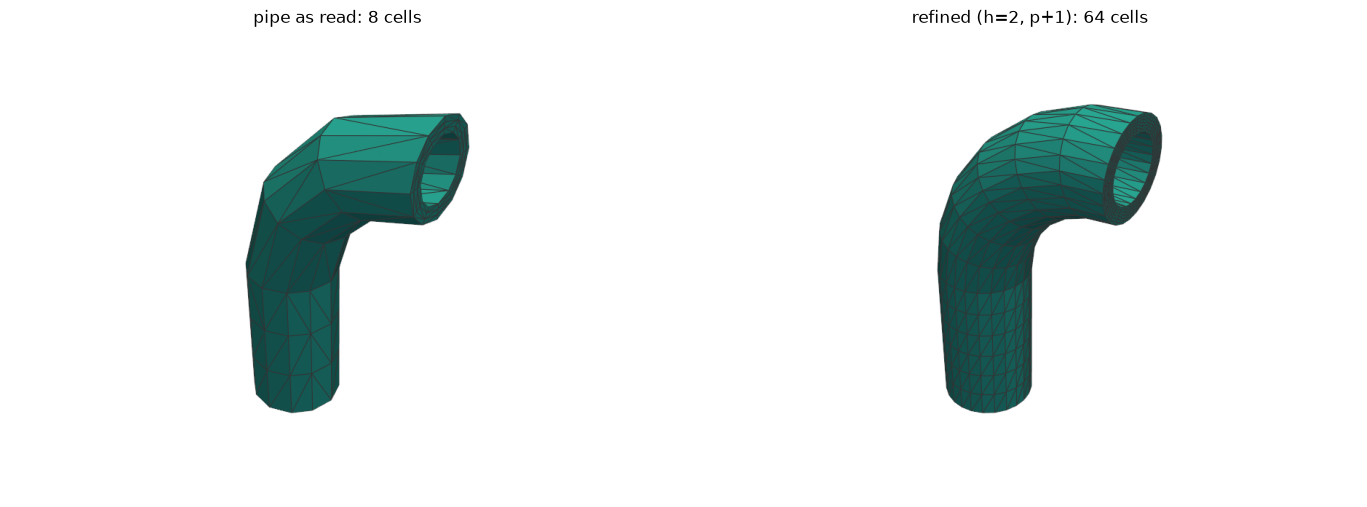

refused: meshio++: iga: a model with a patch topology refines every direction alike (its patches share knot vectors along differently oriented directions)


In [6]:
pipe = mp.read(os.path.join(NURBS, 'pipe-nurbs.mesh'), file_format='mfem')
fine_pipe = mp.iga_refine(pipe, subdivisions=2, elevate=1)
out = os.path.join(TMP, 'pipe_fine.mesh')
mp.write(out, fine_pipe, file_format='mfem')
back = mp.read(out, file_format='mfem')
print(open(out).readline().strip(), '|', len(back.info['nurbs']['patches']), 'patches,',
      back.info['nurbs']['patches'][0]['degrees'].tolist(), 'degrees')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
render(pipe, f'pipe as read: {len(pipe.cells[0].data)} cells', ax=axes[0])
render(fine_pipe, f'refined (h=2, p+1): {len(fine_pipe.cells[0].data)} cells', ax=axes[1])
plt.tight_layout()
plt.show()

try:
    mp.iga_refine(pipe, subdivisions=(2, 3, 2))
except ValueError as exc:
    print('refused:', exc)